# 10 · Final system: the whole person decides the helmet, the head decides the color

```
Photo
 │
 ▼ STEP 1 · YOLOX-s → box of each person                                 (yolox_person_detector.py)
 │
 ├─► STEP 2 · Whole person, letterbox 224×224
 │      → preprocessing + frozen ResNet50 → person vector (2,048)
 │      → output A' (dropout 0.3 → dense 1, sigmoid; 2,048 weights + 1 bias)   ← notebook 08
 │      → P(helmet) < 0.5 → "NO HELMET" (stop)
 │
 └─► STEP 3 · Only if P(helmet) ≥ 0.5: head crop 224×224 (body keypoints)
        → preprocessing + frozen ResNet50 (the same one) → head vector (2,048)
        → output B (dropout 0.3 → dense 5, softmax; 10,240 weights + 5 biases) ← notebook 04
        → highest P(color) ≥ 0.6 → "HELMET <color>"
        → highest P(color) < 0.6 → "HELMET, other color"
```

**Why two inputs:** the whole person gave the highest share of heads found and correct for helmet yes or no (notebooks 07 to 09). But in 224 px the head of a whole person is only ~30 px and the color is lost. So the head crop decides only the color: if the crop is off, the error is a color error, not a safety error.

## "Other color"
To train an "other color" class we would need helmets of other colors (white, blue, …) **labeled by people**. Our photos do not have them and SHWD has no color labels.

Until then, "other color" comes from a **confidence threshold**: softmax spreads the probability over the 5 known colors. If none reaches 0.6, the helmet does not look enough like any of them and we report "other color".

- **0.6 is a starting value, not calibrated.** There are no labeled helmets of other colors to choose it. In our photos the lowest confidence on a correct answer was 0.53 (red on the black background), so some of our own helmets could come out as "other color".

## Head crop for the color (step 3)
With body keypoints, the method of notebook 09.
1. Keypoint R-CNN runs on the photo and gives persons with 17 keypoints.
2. Each YOLOX person is paired with the Keypoint R-CNN person of highest IoU, if that IoU is ≥ 0.5.
3. With its keypoints: head width a = max(ear-to-ear, 2.5 × eye-to-eye, 0.45 × shoulder-to-shoulder); square crop of side 2.0·a centered at (x̄, ȳ − 0.2·a) of the visible face keypoints (details in notebook 09).
4. No pair or no keypoints: the fixed rule of notebook 07.

In [1]:
import xml.etree.ElementTree as ET
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
import torch
from PIL import Image, ImageOps, ImageDraw, ImageFilter, ImageFont
from torchvision.models.detection import keypointrcnn_resnet50_fpn, KeypointRCNN_ResNet50_FPN_Weights
from torchvision.transforms.functional import to_tensor
from yolox_person_detector import detect_persons, intersection, area

keras.utils.set_random_seed(0)
REPO = Path.cwd().parent
SHWD = REPO / "data/VOC2028"
OUTPUTS, MODELS = REPO / "outputs", REPO / "models"
SIZE, MIN_SIDE = 224, 32
COLORS = ["green", "orange", "red", "transparent", "yellow"]
HELMET_THRESHOLD, COLOR_THRESHOLD = 0.5, 0.6

base = keras.models.load_model(MODELS / "helmet_and_color.keras")
inp = keras.Input((SIZE, SIZE, 3))
vectorize = keras.Model(inp, base.get_layer("resnet50")(base.get_layer("resnet_preprocess")(inp)))   # preprocessing + ResNet50
output_Ap = keras.models.load_model(MODELS / "helmet_person_head.keras")       # helmet? (whole person)
output_B = base.get_layer("color_head")                                         # color, 5 classes (our helmets)
vec = lambda X: np.concatenate([vectorize.predict(X[i:i + 512].astype("float32"), batch_size=64, verbose=0) for i in range(0, len(X), 512)])

DEVICE = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
kprcnn = keypointrcnn_resnet50_fpn(weights=KeypointRCNN_ResNet50_FPN_Weights.COCO_V1).eval().to(DEVICE)

## 1. The full system

In [2]:
FACE, SHOULDERS = [0, 1, 2, 3, 4], [5, 6]

def fixed_rule(b):
    x1, y1, x2, y2 = b; h = y2 - y1
    return np.array([(x1 + x2) / 2 - 0.175 * h, y1 - 0.10 * h, (x1 + x2) / 2 + 0.175 * h, y1 + 0.25 * h])

def head_from_keypoints(kp, visible):
    dist = lambda i, j: np.linalg.norm(kp[i] - kp[j]) if visible[i] and visible[j] else 0.0
    a = max(1.0 * dist(3, 4), 2.5 * dist(1, 2), 0.45 * dist(5, 6))
    face = [i for i in FACE if visible[i]]
    if a > 0 and face:
        cx, cy = kp[face].mean(0); cy -= 0.2 * a
    elif a > 0 and all(visible[SHOULDERS]):
        cx, cy = kp[SHOULDERS].mean(0); cy -= 1.1 * a
    else:
        return None
    return np.array([cx - a, cy - a, cx + a, cy + a])                 # side 2.0·a

def color_head_boxes(img, persons):
    # One head box per YOLOX person: Keypoint R-CNN keypoints if there is a pair (IoU ≥ 0.5), else the fixed rule
    with torch.no_grad():
        o = kprcnn([to_tensor(img).to(DEVICE)])[0]
    k = (o["scores"] >= 0.5).cpu().numpy()
    K, kps, vis = o["boxes"].cpu().numpy()[k], o["keypoints"].cpu().numpy()[k][..., :2], o["keypoints_scores"].cpu().numpy()[k] > 2.0
    if not len(K):
        return [fixed_rule(p) for p in persons]
    inter = intersection(persons, K)
    iou = inter / (area(persons)[:, None] + area(K)[None] - inter)
    out = []
    for i, p in enumerate(persons):
        j = iou[i].argmax()
        box = head_from_keypoints(kps[j], vis[j]) if iou[i, j] >= 0.5 else None
        out.append(fixed_rule(p) if box is None else box)
    return out

def letterbox(img, b):
    x1, y1, x2, y2 = np.clip(b, 0, [img.width, img.height, img.width, img.height])
    p = img.crop((x1, y1, x2, y2))
    k = SIZE / max(p.width, p.height)
    p = p.resize((max(1, round(p.width * k)), max(1, round(p.height * k))), Image.BILINEAR)
    canvas = Image.new("RGB", (SIZE, SIZE)); canvas.paste(p, ((SIZE - p.width) // 2, (SIZE - p.height) // 2))
    return np.asarray(canvas)

def analyze(img):
    persons, scores = detect_persons(img)
    if not len(persons):
        return pd.DataFrame()
    p_helmet = output_Ap.predict(vec(np.stack([letterbox(img, p) for p in persons])), verbose=0).ravel()
    res = pd.DataFrame({"person": list(persons), "p_person": scores, "p_helmet": p_helmet, "helmet": p_helmet >= HELMET_THRESHOLD,
                        "head_rect": color_head_boxes(img, persons), "color": None, "p_color": np.nan})
    k = res.helmet.to_numpy()
    if k.any():                                                            # step 3 only for persons with a helmet
        Xc = np.stack([np.asarray(img.crop(tuple(c)).resize((SIZE, SIZE), Image.BILINEAR)) for c in res.head_rect[k]])
        pc = output_B.predict(vec(Xc), verbose=0)
        res.loc[k, "color"] = np.where(pc.max(1) >= COLOR_THRESHOLD, np.array(COLORS)[pc.argmax(1)], "other color")
        res.loc[k, "p_color"] = pc.max(1)
    return res

def draw(img, res):
    # Blur the face; green head box with the color for a helmet, red person box for no helmet
    img = img.copy(); d = ImageDraw.Draw(img)
    font = ImageFont.load_default(size=max(14, img.width // 45)); width = max(3, img.width // 300)
    for _, r in res.iterrows():
        x1, y1, x2, y2 = r.head_rect
        face = tuple(int(v) for v in (x1, (y1 + y2) / 2, x2, y2))
        if face[2] > face[0] and face[3] > face[1]:
            img.paste(img.crop(face).filter(ImageFilter.GaussianBlur(float(max(2, (x2 - x1) / 10)))), face[:2])
        if r.helmet:
            text, col, box = f"HELMET {r.color} {r.p_color:.2f}", "lime", r.head_rect
        else:
            text, col, box = f"NO HELMET {1 - r.p_helmet:.2f}", "red", r.person
        d.rectangle(tuple(box), outline=col, width=width)
        tb = d.textbbox((box[0], max(0, box[1] - font.size - 4)), text, font=font)
        d.rectangle(tb, fill="black"); d.text(tb[:2], text, fill=col, font=font)
    return img

## 2. Evaluation on the SHWD test photos

For each labeled head (side ≥ 32 px) we look for the detected person that holds it (≥ 90% inside its box), with the same assignment as notebook 08.
- **Helmet yes or no:** measured. It must match notebook 08, because the same output A' decides.
- **Color:** **not measured.** SHWD has no color labels. We only show how the predicted colors are spread, and we check the quality by eye in the examples.

We also count the persons found and the labeled heads, as shown in the presentation.

In [3]:
def assign(P, H):
    if not len(P) or not len(H):
        return np.full(len(P), -1)
    frac = intersection(P, H) / area(H)[None]
    h = P[:, 3] - P[:, 1]
    point = np.stack([(P[:, 0] + P[:, 2]) / 2, P[:, 1] + 0.1 * h], 1)
    center_H = np.stack([(H[:, 0] + H[:, 2]) / 2, (H[:, 1] + H[:, 3]) / 2], 1)
    dist = np.linalg.norm(point[:, None] - center_H[None], axis=2) / h[:, None]
    dist[frac < 0.9] = np.inf
    return np.where(np.isinf(dist.min(1)), -1, dist.argmin(1))

test_ids = (SHWD / "ImageSets/Main/test.txt").read_text().split()
rows, persons = [], []
all_heads = {"hat": 0, "person": 0}
for img_id in test_ids:
    root = ET.parse(SHWD / f"Annotations/{img_id}.xml").getroot()
    H, label = [], []
    for o in root.iter("object"):
        if o.findtext("name") not in ("hat", "person"):
            continue
        all_heads[o.findtext("name")] += 1
        b = [int(float(o.find("bndbox").findtext(t))) for t in ("xmin", "ymin", "xmax", "ymax")]
        if min(b[2] - b[0], b[3] - b[1]) >= MIN_SIDE:
            H.append(b); label.append(o.findtext("name"))
    img = ImageOps.exif_transpose(Image.open(SHWD / f"JPEGImages/{img_id}.jpg")).convert("RGB")
    res = analyze(img)
    chosen = assign(np.stack(res.person) if len(res) else np.zeros((0, 4)), np.array(H, float).reshape(-1, 4))
    for k in range(len(res)):
        persons.append({"id": img_id, "p_helmet": res.p_helmet.iloc[k], "has_labeled_head": chosen[k] >= 0})
    for j, (b, c) in enumerate(zip(H, label)):
        who = np.where(chosen == j)[0]
        r = res.iloc[who[res.p_person.iloc[who].argmax()]] if len(who) else None
        rows.append({"id": img_id, "true_helmet": c == "hat",
                     "covered": r is not None, "pred_helmet": None if r is None else bool(r.helmet),
                     "pred_color": None if r is None else r.color})
ev = pd.DataFrame(rows)
persons = pd.DataFrame(persons)
ev.to_csv(OUTPUTS / "10_test_evaluation.csv", index=False)
persons.to_csv(OUTPUTS / "10_test_persons.csv", index=False)

cov = ev[ev.covered]
pd.Series({
    "coverage": ev.covered.mean(),
    "sensitivity no helmet": (cov.pred_helmet[~cov.true_helmet] == False).mean(),
    "specificity helmet": (cov.pred_helmet[cov.true_helmet] == True).mean(),
    "helmet yes/no, found and correct": (ev.covered & (ev.pred_helmet == ev.true_helmet)).mean(),
}).round(3)

coverage                            0.729
sensitivity no helmet               0.987
specificity helmet                  0.976
helmet yes/no, found and correct    0.717
dtype: float64

In [4]:
counts = {
    "test photos": len(test_ids),
    "labeled heads (any size)": all_heads,
    "labeled heads >= 32 px": {"hat": int(ev.true_helmet.sum()), "person": int((~ev.true_helmet).sum())},
    "persons found by YOLOX": len(persons),
    "persons with helmet (P >= 0.5)": int((persons.p_helmet >= HELMET_THRESHOLD).sum()),
    "persons without helmet (P < 0.5)": int((persons.p_helmet < HELMET_THRESHOLD).sum()),
    "persons that hold a labeled head >= 32 px": int(persons.has_labeled_head.sum()),
}
(OUTPUTS / "10_counts.json").write_text(json.dumps(counts, indent=1))
counts

{'test photos': 1517,
 'labeled heads (any size)': {'hat': 1878, 'person': 22558},
 'labeled heads >= 32 px': {'hat': 1283, 'person': 5433},
 'persons found by YOLOX': 10124,
 'persons with helmet (P >= 0.5)': 1669,
 'persons without helmet (P < 0.5)': 8455,
 'persons that hold a labeled head >= 32 px': 5014}

### Confusion matrix of the final system

Rows: the true label from SHWD. Columns: the system answer. "Not found" means no person box held the labeled head. Correct answers are the first two cells of the diagonal.

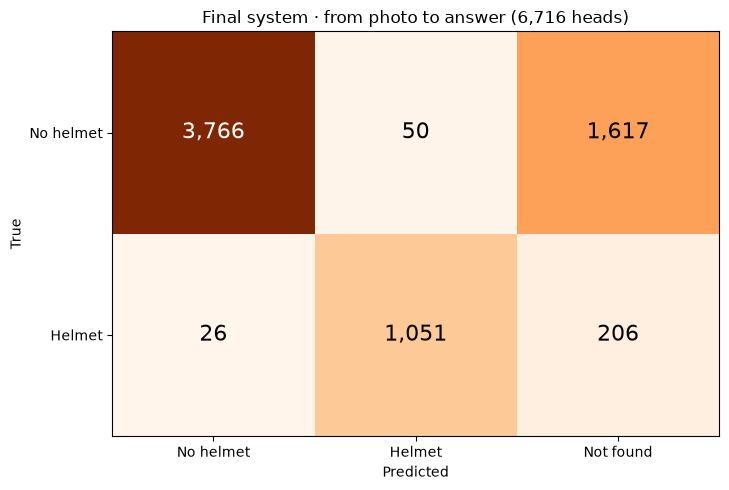

correct: 4,817 of 6,716 = 71.7%


In [5]:
answer = np.where(~ev.covered, "Not found", np.where(ev.pred_helmet == True, "Helmet", "No helmet"))
cm = pd.crosstab(ev.true_helmet.map({False: "No helmet", True: "Helmet"}), answer).reindex(
    index=["No helmet", "Helmet"], columns=["No helmet", "Helmet", "Not found"], fill_value=0)
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(cm.values, cmap="Oranges")
for (i, j), v in np.ndenumerate(cm.values):
    ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=16, color="white" if v > cm.values.max() / 2 else "black")
ax.set_xticks(range(3), cm.columns); ax.set_yticks(range(2), cm.index)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"Final system · from photo to answer ({len(ev):,} heads)")
plt.tight_layout(); plt.savefig(OUTPUTS / "10_confusion_matrix_final.png", dpi=150); plt.show()
correct = cm.loc["No helmet", "No helmet"] + cm.loc["Helmet", "Helmet"]
print(f"correct: {correct:,} of {len(ev):,} = {correct / len(ev):.1%}")

In [6]:
# Predicted colors for labeled heads with a helmet that the system called "HELMET" (no true color label exists)
ev[ev.true_helmet & (ev.pred_helmet == True)].pred_color.value_counts(normalize=True).round(3)

pred_color
orange         0.383
other color    0.351
yellow         0.176
transparent    0.046
red            0.026
green          0.018
Name: proportion, dtype: float64

## 3. Examples (the same photos as notebooks 07 and 09)

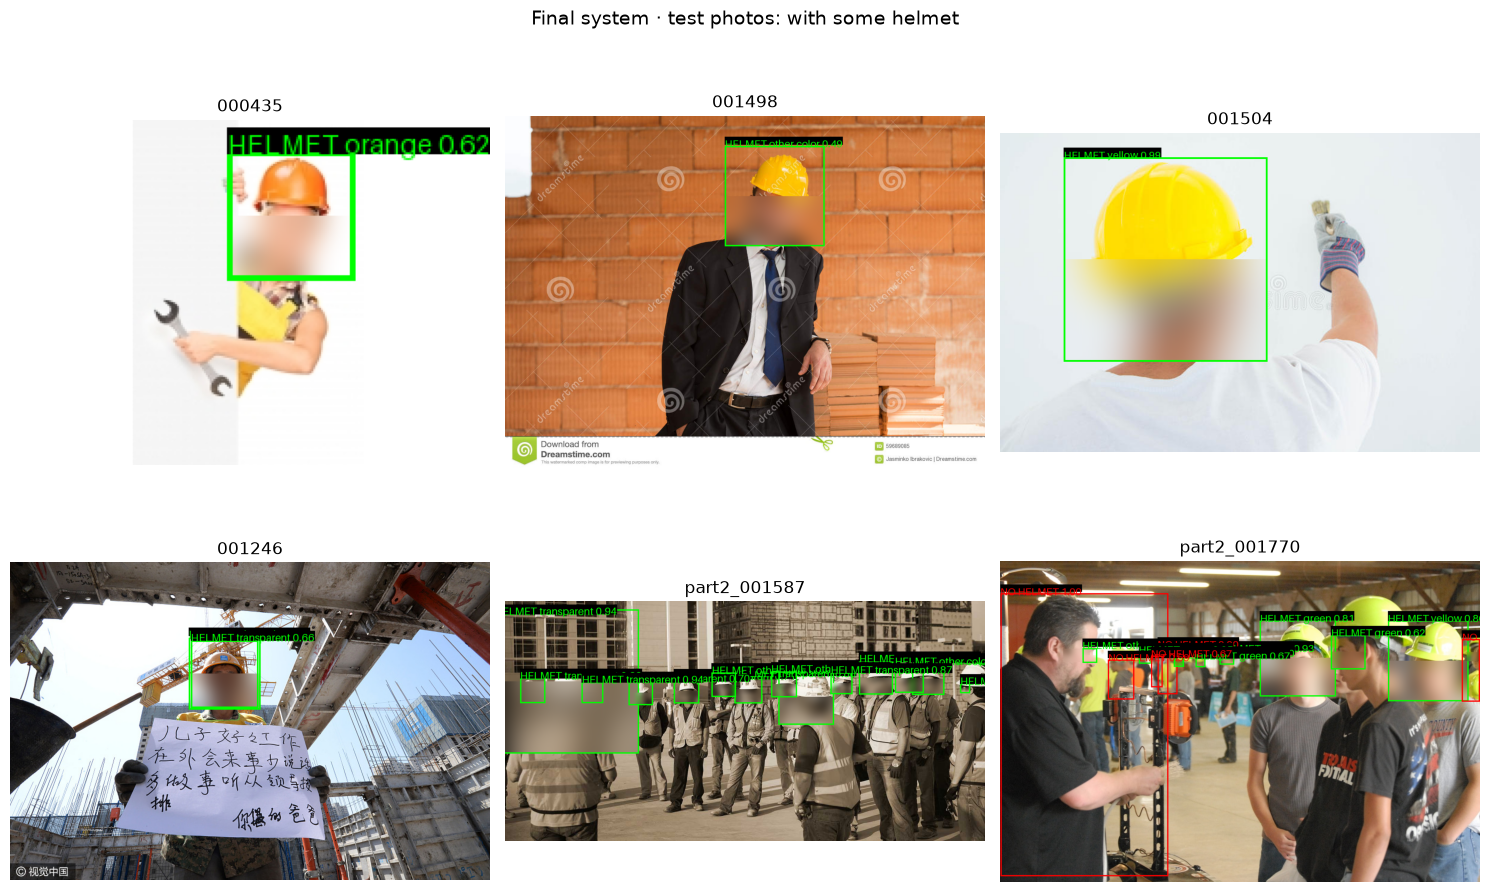

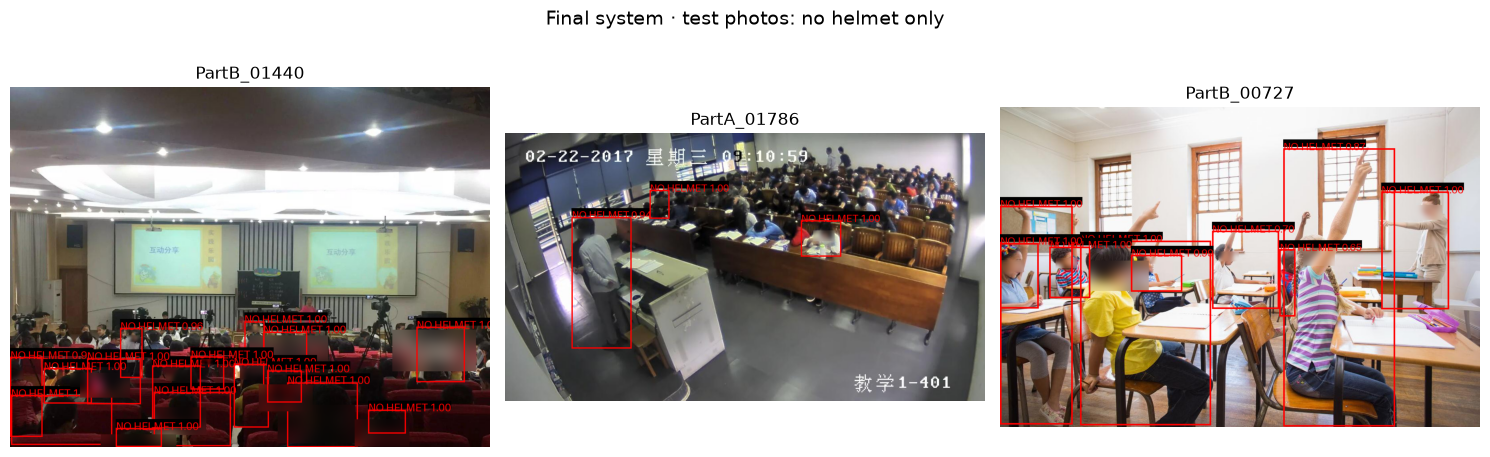

In [7]:
ev07 = pd.read_csv(OUTPUTS / "07_test_evaluation.csv")
for kind, n, file in [("with some helmet", 6, "10_examples_helmet.png"), ("no helmet only", 3, "10_examples_no_helmet.png")]:
    examples = ev07[ev07.kind == kind].id.drop_duplicates().sample(n, random_state=1)
    fig, axes = plt.subplots(n // 3, 3, figsize=(15, 5 * n // 3), squeeze=False)
    for ax, img_id in zip(axes.ravel(), examples):
        img = ImageOps.exif_transpose(Image.open(SHWD / f"JPEGImages/{img_id}.jpg")).convert("RGB")
        ax.imshow(draw(img, analyze(img))); ax.set_title(img_id); ax.axis("off")
    fig.suptitle(f"Final system · test photos: {kind}", fontsize=14)
    plt.tight_layout(); plt.savefig(OUTPUTS / file, dpi=100); plt.show()

## 4. Save the final system

One `.keras` file with **two inputs** (person 224 × 224 and head 224 × 224) and two outputs. ResNet50 is the same layer for both inputs, so its weights are stored once.

In [8]:
person_in, head_in = keras.Input((SIZE, SIZE, 3), name="person_224"), keras.Input((SIZE, SIZE, 3), name="head_224")
system = keras.Model([person_in, head_in], {"helmet": output_Ap(vectorize(person_in)), "color": output_B(vectorize(head_in))},
                     name="helmet_color_system")
system.summary()
system.save(MODELS / "final_system.keras")
(MODELS / "final_system_config.json").write_text(json.dumps({"color_classes": COLORS, "helmet_threshold": HELMET_THRESHOLD,
                                                             "color_threshold": COLOR_THRESHOLD}))

Model: "helmet_color_system"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ head_224            │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ person_224          │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_4        │ (None, 2048)      │ 23,587,724 │ person_224[0][0], │
│ (Functional)        │                   │            │ head_224[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ color_head          │ (None, 5)         │     10,245 │ functional_4[1][… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 1)         │      2,049 │ functional_4[0][… │
│ (Sequential)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,600,018 (90.03 MB)

 Trainable params: 12,294 (48.02 KB)

 Non-trainable params: 23,587,724 (89.98 MB)

## 5. Limits
- Many heads without a helmet that the model marked as helmet wear a cap, a hat or a hood. Most SHWD heads without a helmet are bare heads, so the model rarely saw caps.
- The color was trained on one helmet per color, and none was worn by a person. The color on real photos was checked only by eye.
- SHWD and COCO limit this work to a research prototype.